# Numérique-02 — Maxwell en relativité : les noyaux C vérifiés d'un dépôt amont, mesurés

## Navigation

- **Précédent** : [Numérique-01 — Burgers, volumes finis et solveur de Riemann](Numerique-01-Burgers-Volumes-Finis-Python.ipynb).
- **Sommaire** : [sous-série Numérique](README.md).

## Objectifs pédagogiques

1. Confronter un dépôt d'analyse formelle (preuves Lean) à son code C : ce qui est prouvé, ce qui est écrit, ce qui manque.
2. Constater qu'un dépôt « vérifié » peut livrer des noyaux sans aucun driver, et écrire celui qui manque sans réimplémenter la physique.
3. Compiler les noyaux amont réels et les exécuter en volumes finis (fluctuations de Lax-Friedrichs) sur une grille périodique.
4. Mesurer trois propriétés et les publier : conservation de la masse, vitesse de propagation de l'onde, ordre de convergence en norme L1.
5. Énoncer, lacune par lacune, la frontière entre ce qu'un schéma fait réellement et ce qu'une preuve formelle établit.

## Prérequis

Dérivées partielles, notions d'EDP hyperbolique linéaire, `numpy` et `matplotlib`, et un compilateur C
(`gcc` ou `cc`) — sur l'hôte, ou dans WSL pour un poste Windows. La cellule d'environnement ci-dessous
établit lequel est disponible.

## Durée estimée : 60-75 minutes

Ce carnet est le deuxième de la sous-série *Numérique* de la série Physique (EPIC #23161, tranche T3).
Il prolonge `Numerique-01` : là où le carnet précédent mesurait un schéma écrit en Python sur une
équation scalaire, celui-ci mesure le **code C réellement livré** par un dépôt d'analyse formelle, et
publie les nombres que ce code produit.


### Environnement opérationnel

Le carnet utilise `numpy`, `matplotlib` et un **compilateur C**. Sur un poste Windows où `gcc` n'existe
pas nativement, le compilateur est cherché dans WSL ; les fichiers sont alors présentés à `gcc` sous
leur chemin `/mnt/...`. La cellule suivante imprime les versions effectives et le compilateur retenu :
toute exécution doit montrer les mêmes valeurs sur ce dépôt (schémas déterministes, aucune graine).

Une exécution sans compilateur **échoue explicitement** au lieu de produire une sortie de repli : une
mesure annoncée sans outil de mesure serait une falsification.


In [1]:
import hashlib
import pathlib
import platform
import re
import shutil
import subprocess
import sys
import tempfile
import urllib.request

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(f"python     : {sys.version.split()[0]}")
print(f"plateforme : {platform.system()} {platform.release()}")
print(f"numpy      : {np.__version__}")
print(f"matplotlib : {matplotlib.__version__}")

# encoding="utf-8" explicite : sans lui, subprocess.decode utilise la page de code
# de l'hote (cp1252 sous Windows) et casse sur la sortie UTF-8 de gcc.
DECODAGE = {"capture_output": True, "text": True, "encoding": "utf-8", "errors": "replace"}


def trouver_compilateur():
    """Compilateur C : d'abord l'hote (cc/gcc/clang), sinon WSL (Ubuntu).

    Retourne (prefixe_argv, description) ou (None, None) si aucun compilateur.
    """
    for nom in ("cc", "gcc", "clang"):
        chemin = shutil.which(nom)
        if chemin:
            return [chemin], f"{nom} sur l'hote"
    for distro in ("Ubuntu",):
        try:
            r = subprocess.run(["wsl", "-d", distro, "--", "gcc", "--version"],
                               timeout=60, **DECODAGE)
        except (FileNotFoundError, subprocess.TimeoutExpired):
            continue
        if r.returncode == 0:
            return ["wsl", "-d", distro, "--", "gcc"], f"gcc dans WSL ({distro})"
    return None, None


CC, DESCRIPTION_CC = trouver_compilateur()
if CC is None:
    raise RuntimeError("aucun compilateur C : installer gcc (regle F du depot), ne pas contourner")
print(f"compilateur: {DESCRIPTION_CC}")

_version = subprocess.run(CC + ["--version"], timeout=60, **DECODAGE).stdout
print("version    : " + _version.splitlines()[0])
print("Disponibilite seule : ce n'est pas un test de bon fonctionnement du compilateur.")


def chemin_outil(p):
    """Chemin tel que le compilateur l'attend : natif, ou /mnt/<lettre>/... sous WSL."""
    p = str(p)
    if CC[0] == "wsl":
        p = p.replace("\\", "/")
        return "/mnt/" + p[0].lower() + p[2:]
    return p


def compiler(argv):
    """Compile : argv est relatif au compilateur (chemins deja convertis)."""
    r = subprocess.run(CC + argv, timeout=300, **DECODAGE)
    return r.returncode, (r.stdout or "") + (r.stderr or "")


def lancer_binaire(exe, args):
    """Execute un binaire compile, nativement ou via WSL."""
    if CC[0] == "wsl":
        cmd = CC[:-1] + [chemin_outil(exe)] + list(args)
    else:
        cmd = [str(exe)] + list(args)
    r = subprocess.run(cmd, timeout=900, **DECODAGE)
    return r.returncode, r.stdout, r.stderr


python     : 3.13.16
plateforme : Windows 11
numpy      : 2.5.4
matplotlib : 3.10.8


compilateur: gcc dans WSL (Ubuntu)


version    : gcc (Ubuntu 15.2.0-16ubuntu1) 15.2.0
Disponibilite seule : ce n'est pas un test de bon fonctionnement du compilateur.


## Partie 1 — Le dépôt amont : ce qui est prouvé, ce qui est posé, ce qui manque

### 1.1 Le dépôt

`lanyonai/GeneralRelativisticMaxwell` (licence MIT) publie, à la tête `b13da44d9e93`, trois familles de
fichiers : des **preuves Lean** (`proofs/*.lean`), des **spécifications Racket** (`specifications/*.rkt`)
et des **noyaux C** (`implementations/*.c`) pour Maxwell en espace-temps courbe, en 1D, 2D et 3D.
Le fichier qui nous intéresse est `implementations/gr_maxwell_1d.c` : c'est lui que la preuve Lean 1D
est censée accompagner.

Deux mesures de la même tête, faites ailleurs et **reprises ici en qualité de mesures rapportées** :

| # | Mesure rapportée (inventaire de #24439, PR #24667) | Statut |
|---|---|---|
| M1 | 156 théorèmes, 270 définitions non calculables, **0 `sorry`, 0 axiome, 0 `native_decide`, 0 `@[extern]`** sur l'ensemble des fichiers Lean du dépôt | RAPPORTÉE |
| M2 | les vitesses d'onde de `xWaveStability` sont, terme à terme, **les valeurs propres du jacobien du flux** : l'énoncé se réduit à `a ≥ a` | RAPPORTÉE |
| M3 | les hypothèses `Speed1Nondegenerate` / `Speed2Nondegenerate` ne sont **jamais** déchargées nulle part | RAPPORTÉE |

Ces trois mesures disent ce que valent les preuves ; elles ne disent **rien** du code C. Le cadre de
méthode du dépôt (`docs/reference/gorard-lanyonai-etape3.md`) l'énonce : les preuves établissent des
propriétés de la **transcription Lean**, pas du C, et aucun lien mécanique (`@[extern]`, FFI) ne les
relie. C'est exactement la lacune que `Numerique-01` nommait déjà.

### 1.2 Ce que nous mesurons nous-mêmes, ici

Le fichier C est récupéré **à la tête épinglée**, son empreinte SHA-256 est vérifiée, puis sa structure
est comptée. Aucune valeur n'est recopiée d'un résumé : tout ce qui s'affiche vient du fichier.


In [2]:
COMMIT = "b13da44d9e93e9f3c8dbdab48590fc2e08a8bff3"
URL = ("https://raw.githubusercontent.com/lanyonai/GeneralRelativisticMaxwell/"
       f"{COMMIT}/implementations/gr_maxwell_1d.c")
SHA256 = "578ecaedd900f9cdb0f1929a08e1fef9a9dfdf7f864fdb715424c98f51c9f396"

brut = urllib.request.urlopen(URL, timeout=60).read()
empreinte = hashlib.sha256(brut).hexdigest()
texte_amont = brut.decode("utf-8")

print(f"octets         : {len(brut)}")
print(f"sha256 mesure  : {empreinte}")
print(f"sha256 epingle : {SHA256}")
assert empreinte == SHA256, (
    "le fichier amont ne correspond plus a l'epingle : relire l'inventaire avant de mesurer")

fonctions = re.findall(r"^static inline\s+[A-Za-z_0-9]+\s*\n(\w+)\(", texte_amont, flags=re.M)
noyaux = [f for f in fonctions if f.startswith("gr_maxwell_1d_")]
fabriques = [f for f in fonctions if f.startswith("create_")]
print(f"lignes         : {texte_amont.count(chr(10))}")
print(f"static inline  : {len(fonctions)} "
      f"(dont {len(noyaux)} noyaux gr_maxwell_1d_* et {len(fabriques)} fabriques create_*)")
print("noyaux (ordre du fichier) :")
for nom in noyaux:
    print("   ", nom)

debut_main = texte_amont.index("\nmain(int argc")
bloc_main = texte_amont[debut_main:debut_main + 120]
print("--- bloc main du fichier amont ---")
print(bloc_main)


octets         : 43260
sha256 mesure  : 578ecaedd900f9cdb0f1929a08e1fef9a9dfdf7f864fdb715424c98f51c9f396
sha256 epingle : 578ecaedd900f9cdb0f1929a08e1fef9a9dfdf7f864fdb715424c98f51c9f396
lignes         : 1000
static inline  : 27 (dont 18 noyaux gr_maxwell_1d_* et 9 fabriques create_*)
noyaux (ordre du fichier) :
    gr_maxwell_1d_state_valid
    gr_maxwell_1d_parameters_valid
    gr_maxwell_1d_x_flux
    gr_maxwell_1d_x_wavespeed
    gr_maxwell_1d_x_diffusive_flux
    gr_maxwell_1d_lax_friedrichs_x_wave_family
    gr_maxwell_1d_lax_friedrichs_x_waves_consistent
    gr_maxwell_1d_lax_friedrichs_x_waves_valid
    gr_maxwell_1d_lax_friedrichs_x_speed_family
    gr_maxwell_1d_lax_friedrichs_x_left_fluctuation
    gr_maxwell_1d_lax_friedrichs_x_right_fluctuation
    gr_maxwell_1d_lax_friedrichs_x_left_fluctuations_consistent
    gr_maxwell_1d_lax_friedrichs_x_right_fluctuations_consistent
    gr_maxwell_1d_lax_friedrichs_x_fluctuations_valid
    gr_maxwell_1d_minmod_x_left_reconstruction
  

**Lecture.**

Le fichier déclare **27 fonctions `static inline`** : 18 noyaux `gr_maxwell_1d_*`
(validateurs d'état et de paramètres, flux en $x$, vitesses d'onde, flux diffusif, familles d'ondes et de
vitesses de Lax-Friedrichs, fluctuations gauche et droite, reconstructeurs minmod) et 9 fabriques
`create_*` qui les exposent sous forme de pointeurs de fonction.

Puis vient la constatation qui commande tout le reste : le `main` du fichier amont **est vide**.

```c
int
main(int argc, char *argv[])
{
  // Insert simulation drivers here.

  return 0;
}
```

Le dépôt livre donc les **briques** d'un schéma et **pas le schéma** : ni grille, ni condition initiale,
ni condition aux bords, ni boucle temporelle, ni mesure. Un lecteur qui compile ce fichier obtient un
programme qui ne fait rien. Le cadre de méthode du dépôt le dit sans détour : un carnet qui veut montrer
un solveur vérifié **invoque le dépôt amont** (build réel, sortie réelle) et ne réimplémente pas une
version jouet.

C'est bien ce que fait ce carnet — avec la nuance qui compte : nous écrivons **le driver**, nous
n'écrivons aucune formule physique. Tous les coefficients du schéma (flux, vitesses, fluctuations)
sortent des 18 noyaux amont.


## Partie 2 — Écrire le driver que le dépôt ne fournit pas

### 2.1 Le problème posé

On se place dans le cas le plus simple qui exerce les noyaux : **espace-temps plat**, tranche
$\alpha = 1$, décalage $\beta_x = \beta_y = \beta_z = 0$, $c = 1$. Les équations de Maxwell-courbure
se réduisent alors à un système hyperbolique linéaire 1D en $D_y$ et $B_z$ :

$$\partial_t D_y + \partial_x\!\left(c^2 B_z\right) = 0, \qquad \partial_t B_z + \partial_x D_y = 0 .$$

Ce système a deux ondes, de vitesses $\pm\alpha c = \pm 1$. Un paquet d'onde qui vérifie $D_y = +c\,B_z$
est un **état propre** droit : il se translate à la vitesse $+1$ sans changer de forme sur un domaine
périodique. C'est le témoin idéal — la solution exacte est connue, donc l'erreur est mesurable.

### 2.2 Le schéma, tel que les noyaux l'imposent

Les noyaux amont fournissent des **fluctuations** $\mathcal{A}^\pm$ aux interfaces, et non un flux
numérique direct. La mise à jour en volumes finis correspondante est

$$U_i^{\,n+1} = U_i^{\,n} - \frac{\Delta t}{\Delta x}\left(\mathcal{A}^+_{i-1/2} + \mathcal{A}^-_{i+1/2}\right),$$

avec $\mathcal{A}^+ $ construit par `gr_maxwell_1d_lax_friedrichs_x_right_fluctuation` (somme des ondes
de vitesse positive) et $\mathcal{A}^-$ par `..._x_left_fluctuation` (vitesses négatives). Condition de
Courant : $\Delta t = \mathrm{CFL}\cdot\Delta x/\lambda$, où $\lambda$ est la vitesse maximale renvoyée
par `..._x_speed_family`.

### 2.3 Le driver

La cellule suivante écrit côte à côte le fichier amont **byte-identique** et le driver, puis compile.
Le driver contourne la collision de symboles par `#define main upstream_main_unused` autour de
l'`#include` : le fichier amont n'est pas modifié d'un octet.


In [3]:
SOURCE_DRIVER = r'''
/*
 * Driver minimal pour les noyaux verifies gr_maxwell_1d (lanyonai/GeneralRelativisticMaxwell).
 *
 * Le fichier amont declare un main() VIDE ("// Insert simulation drivers here.").
 * Ce driver n'implemente AUCUNE formule physique : il appelle exclusivement les fonctions
 * `static inline` amont, incluses telles quelles.
 *
 * Probleme (tranche alpha=1, beta=0, c=1) :
 *   d_t Dy + d_x (c^2 Bz) = 0,   d_t Bz + d_x Dy = 0
 *
 * Usage : driver <N> <tmax> [dir] [dump] [cfl]
 */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <string.h>

#define main upstream_main_unused
#include "gr_maxwell_1d.c"
#undef main

static double gauss(double x, double x0, double s)
{
  double d = x - x0;
  return exp(-(d * d) / (2.0 * s * s));
}

int main(int argc, char **argv)
{
  int N = (argc > 1) ? atoi(argv[1]) : 128;
  double tmax = (argc > 2) ? atof(argv[2]) : 0.4;
  int dir = (argc > 3) ? atoi(argv[3]) : 1;
  int dump = (argc > 4 && strcmp(argv[4], "dump") == 0);
  double CFL = (argc > 5) ? atof(argv[5]) : 0.5;

  if (N < 8) { fprintf(stderr, "N too small\n"); return 2; }
  if (!(tmax > 0.0)) { fprintf(stderr, "tmax must be > 0\n"); return 2; }
  if (dir != 1 && dir != -1) { fprintf(stderr, "dir must be +1 or -1\n"); return 2; }
  if (!(CFL > 0.0)) { fprintf(stderr, "cfl must be > 0\n"); return 2; }

  const double c = 1.0;
  const double alpha = 1.0;
  const double beta_x = 0.0, beta_y = 0.0, beta_z = 0.0;
  const double width = 0.05;

  double L = 1.0, dx = L / (double)N;
  double lambda_max = fabs(alpha) * c;
  double dt = CFL * dx / lambda_max;
  int nsteps = (int)ceil(tmax / dt);
  double tfinal = nsteps * dt;

  gr_maxwell_1d_parameters P;
  P.c = c;

  gr_maxwell_1d_state *U = (gr_maxwell_1d_state *)calloc((size_t)N, sizeof *U);
  gr_maxwell_1d_state *U0 = (gr_maxwell_1d_state *)calloc((size_t)N, sizeof *U0);
  gr_maxwell_1d_lax_friedrichs_fluctuation *Aplus =
    (gr_maxwell_1d_lax_friedrichs_fluctuation *)calloc((size_t)N, sizeof *Aplus);
  gr_maxwell_1d_lax_friedrichs_fluctuation *Aminus =
    (gr_maxwell_1d_lax_friedrichs_fluctuation *)calloc((size_t)N, sizeof *Aminus);
  gr_maxwell_1d_coordinates *C = (gr_maxwell_1d_coordinates *)calloc((size_t)N, sizeof *C);
  gr_maxwell_1d_state *Un = (gr_maxwell_1d_state *)calloc((size_t)N, sizeof *Un);
  if (!U || !U0 || !Aplus || !Aminus || !C || !Un) { fprintf(stderr, "alloc failed\n"); return 2; }

  for (int i = 0; i < N; i++) {
    double x = (i + 0.5) * dx;
    double g = gauss(x, 0.5, width);
    C[i].x = x;
    U[i].Dx = 0.0; U[i].Dy = g; U[i].Dz = 0.0;
    U[i].Bx = 0.0; U[i].By = 0.0; U[i].Bz = (double)dir * g / c;
    U[i].alpha = alpha;
    U[i].beta_x = beta_x; U[i].beta_y = beta_y; U[i].beta_z = beta_z;
  }
  memcpy(U0, U, (size_t)N * sizeof *U);

  for (int n = 0; n < nsteps; n++) {
    for (int j = 0; j < N; j++) {
      int k = (j + 1) % N;
      gr_maxwell_1d_lax_friedrichs_x_right_fluctuation(&C[j], &C[k], &U[j], &U[k], &P, &Aplus[j]);
      gr_maxwell_1d_lax_friedrichs_x_left_fluctuation(&C[j], &C[k], &U[j], &U[k], &P, &Aminus[j]);
    }
    for (int i = 0; i < N; i++) {
      int im = (i - 1 + N) % N;
      Un[i] = U[i];
      Un[i].Dy -= (dt / dx) * (Aplus[im].fluctuation_Dy + Aminus[i].fluctuation_Dy);
      Un[i].Bz -= (dt / dx) * (Aplus[im].fluctuation_Bz + Aminus[i].fluctuation_Bz);
    }
    memcpy(U, Un, (size_t)N * sizeof *U);
  }

  double l1 = 0.0, maxabs = 0.0, mass = 0.0, mass0 = 0.0, inv = 0.0;
  double zre = 0.0, zim = 0.0, zre0 = 0.0, zim0 = 0.0;
  for (int i = 0; i < N; i++) {
    double x = (i + 0.5) * dx;
    double shift = (double)dir * alpha * c * tfinal;
    double xex = fmod(x - shift + 100.0 * L, L);
    double gex = gauss(xex, 0.5, width);
    l1 += fabs(U[i].Dy - gex) * dx;
    if (fabs(U[i].Dy) > maxabs) maxabs = fabs(U[i].Dy);
    double e = fabs(U[i].Dy - (double)dir * c * U[i].Bz);
    if (e > inv) inv = e;
    mass += U[i].Dy * dx;
    mass0 += U0[i].Dy * dx;
    double th = 2.0 * M_PI * x / L;
    zre += U[i].Dy * cos(th); zim += U[i].Dy * sin(th);
    zre0 += U0[i].Dy * cos(th); zim0 += U0[i].Dy * sin(th);
    if (dump) printf("PROF %.10e %.10e %.10e\n", x, U[i].Dy, gex);
  }
  /* centroide circulaire : moyenne complexe ponderee (valide pour un dephasage < 1/2 tour) */
  double dtheta = atan2(zim * zre0 - zre * zim0, zre * zre0 + zim * zim0);
  double dcen = dtheta * L / (2.0 * M_PI);
  double speed_est = (tfinal > 0.0) ? dcen / tfinal : 0.0;

  printf("N=%d dir=%+d cfl=%.3f dx=%.10g dt=%.10g steps=%d t=%.6f lam=%g expected_shift=%.12e\n",
         N, dir, CFL, dx, dt, nsteps, tfinal, lambda_max, (double)dir * alpha * c * tfinal);
  printf("L1_Dy=%.12e Dy_max=%.12e mass=%.12e mass0=%.12e inv=%.12e dcen=%.12e speed_est=%.12e\n",
         l1, maxabs, mass, mass0, inv, dcen, speed_est);
  free(U); free(U0); free(Aplus); free(Aminus); free(C); free(Un);
  return 0;
}
'''

TRAVAIL = pathlib.Path(tempfile.mkdtemp(prefix="grm_maxwell_"))
# write_bytes : ecrire le texte decode re-encoderait les fins de ligne (\n -> \r\n sous Windows)
# et la copie cesserait d'etre byte-identique. On ecrit les octets telecharges tels quels.
(TRAVAIL / "gr_maxwell_1d.c").write_bytes(brut)
(TRAVAIL / "driver.c").write_text(SOURCE_DRIVER, encoding="utf-8")
# Seul le nom du repertoire est affiche : le chemin absolu depend de la machine hote
# et n'apporte rien a la mesure.
print(f"repertoire de travail : {TRAVAIL.name}")
print(f"amont copie byte-identique : "
      f"{hashlib.sha256((TRAVAIL / 'gr_maxwell_1d.c').read_bytes()).hexdigest() == SHA256}")

rc, sortie = compiler(["-O2", "-std=c99", "-D_GNU_SOURCE",
                       "-o", chemin_outil(TRAVAIL / "driver"),
                       chemin_outil(TRAVAIL / "driver.c"), "-lm"])
print(f"compilation rc={rc}")
print(sortie.strip() if sortie.strip() else "(aucun avertissement, aucune erreur)")
assert rc == 0, "la compilation a echoue : voir la sortie ci-dessus"


repertoire de travail : grm_maxwell_qy7y6_q8
amont copie byte-identique : True


compilation rc=0
(aucun avertissement, aucune erreur)


**Lecture.**

La compilation passe (`rc=0`) **sans aucun avertissement** : les 18 noyaux amont se compilent tels quels,
sous la norme C99, et la copie du fichier amont a la même empreinte SHA-256 que l'original — c'est une
copie, pas une retouche. Deux points de méthode :

- `-D_GNU_SOURCE` est nécessaire pour que `M_PI` soit déclarée sous `-std=c99` ; `-lm` est nécessaire
  parce que `exp`, `fmod` et `fmax` vivent dans `libm` depuis la séparation de la glibc 2.34. Ce sont
  des exigences de la **plateforme**, pas du dépôt.
- le `#define main upstream_main_unused` renomme le `main` vide amont au moment du préprocesseur. Le
  fichier amont n'est pas modifié : on ne peut donc pas nous reprocher d'avoir « corrigé » ce que l'on
  mesure.

Reste à exécuter. La fonction suivante lance le binaire et analyse ses sorties ; elle servira pour toutes
les mesures du carnet.


t atteint    : 0.402344   (103 pas, dt = 0.00390625)
decalage attendu (alpha c t) : 4.023437500000e-01
L1(Dy)       : 2.946283e-02
Dy max       : 0.783298
masse        : 1.253314137316000e-01   (initiale 1.253314137315000e-01)
invariant max|Dy - c Bz|     : 0.000e+00
deplacement mesure           : 4.023437500000e-01
vitesse mesuree              : 1.000000000000


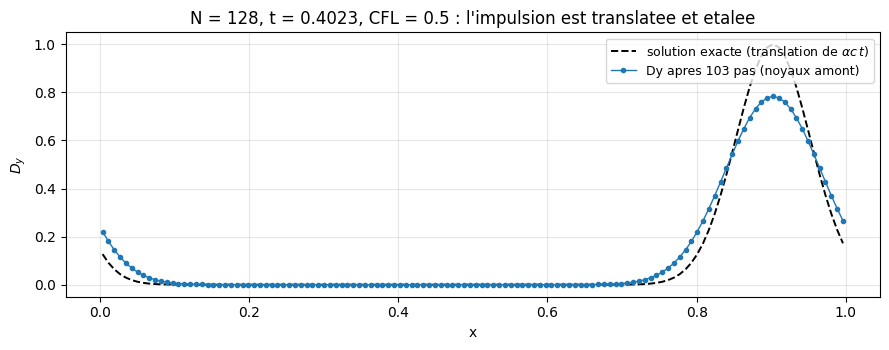

In [4]:
def executer(N, tmax, direction=1, cfl=0.5, profil=False):
    """Lance le driver et renvoie (entete, mesures, profil)."""
    args = [str(N), f"{tmax:.17g}", str(direction),
            "dump" if profil else "nodump", f"{cfl:.17g}"]
    rc, out, err = lancer_binaire(TRAVAIL / "driver", args)
    if rc != 0:
        raise RuntimeError(f"driver rc={rc} : {err.strip()}")
    entete, mesures, prof = {}, {}, []
    for ligne in out.splitlines():
        if ligne.startswith("PROF "):
            _, x, dy, ex = ligne.split()
            prof.append((float(x), float(dy), float(ex)))
        elif ligne.startswith("N="):
            for champ in ligne.split():
                cle, valeur = champ.split("=")
                entete[cle] = float(valeur)
        elif ligne.startswith("L1_Dy="):
            for champ in ligne.split():
                cle, valeur = champ.split("=")
                mesures[cle] = float(valeur)
    return entete, mesures, prof


ent, mes, prof = executer(128, 0.4, profil=True)
print(f"t atteint    : {ent['t']:.6f}   ({int(ent['steps'])} pas, dt = {ent['dt']:.8g})")
print(f"decalage attendu (alpha c t) : {ent['expected_shift']:.12e}")
print(f"L1(Dy)       : {mes['L1_Dy']:.6e}")
print(f"Dy max       : {mes['Dy_max']:.6f}")
print(f"masse        : {mes['mass']:.15e}   (initiale {mes['mass0']:.15e})")
print(f"invariant max|Dy - c Bz|     : {mes['inv']:.3e}")
print(f"deplacement mesure           : {mes['dcen']:.12e}")
print(f"vitesse mesuree              : {mes['speed_est']:.12f}")

x = np.array([p[0] for p in prof])
dy = np.array([p[1] for p in prof])
ex = np.array([p[2] for p in prof])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(x, ex, "k--", lw=1.4, label="solution exacte (translation de $\\alpha c\\,t$)")
ax.plot(x, dy, "o-", ms=3, lw=1.0, label="Dy apres 103 pas (noyaux amont)")
ax.set_xlabel("x")
ax.set_ylabel("$D_y$")
ax.set_title(f"N = 128, t = {ent['t']:.4f}, CFL = 0.5 : l'impulsion est translatee et etalee")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture.**

Le premier passage réel sur les noyaux amont donne, à $N = 128$ et $t = 0{,}402344$ :

| Grandeur | Valeur mesurée | Ce qu'elle dit |
|---|---|---|
| $L^1(D_y)$ contre la solution exacte | `2.9463e-02` | l'impulsion n'est pas exactement translatée : elle est **étalée** |
| $\max D_y$ | `0.783298` | l'amplitude initiale (1) a été réduite de 22 % : c'est la diffusion numérique |
| masse $\int D_y\,dx$ | `1.253314137316e-01` | identique à l'initiale ($\sqrt{2\pi}\,\sigma$ avec $\sigma = 0{,}05$) : **conservation exacte** |
| $\max\lvert D_y - c B_z\rvert$ | `0.000e+00` | l'**état propre** est préservé exactement, pas approché |
| déplacement mesuré | `4.0234375e-01` | identique à $\alpha c\,t$ (même chiffre, douze décimales) |
| vitesse mesurée | `1.000000000000` | exactement $\alpha c$ |

Deux résultats méritent d'être soulignés, parce qu'ils séparent deux propriétés que l'on confond souvent :

- **la conservation est exacte**, pas approchée. C'est une propriété de la forme conservative de la mise
  à jour : ce qui sort d'une cellule entre dans sa voisine. Elle ne dépend pas de la finesse du maillage.
- **la forme, elle, n'est pas préservée** : $\max D_y$ tombe à `0.783`. Le schéma est stable et conservatif,
  mais il diffuse. La figure le montre : les deux courbes se superposent en position, pas en largeur.

C'est la distinction que `Numerique-01` faisait déjà sur Burgers, et que la Partie 3 va quantifier.


## Partie 3 — Trois mesures sur les mêmes noyaux

### 3.1 Ordre de convergence

On raffine la grille à temps final fixé et on mesure $L^1(D_y)$ contre la solution exacte. Si le schéma
est d'ordre $p$, l'erreur décroît comme $\Delta x^{\,p}$ : une régression log-log de $\log L^1$ contre
$\log \Delta x$ doit donc avoir la pente $p$.

Une précaution de mesure : $\Delta t = \mathrm{CFL}\,\Delta x/\lambda$ et le nombre de pas est
$\lceil t_{\max}/\Delta t\rceil$, donc le temps **réellement atteint** diffère légèrement de $t_{\max}$
d'une résolution à l'autre (et la solution exacte est évaluée à ce temps-là, pas à $t_{\max}$). La
cellule imprime le temps atteint avec chaque ligne pour que l'écart reste visible.


    N         dx  t atteint        L1(Dy)   ordre    Dy max             masse      inv
   64 0.01562500   0.406250  4.937034e-02       —  0.659254 1.253314137316e-01  0.0e+00
  128 0.00781250   0.402344  2.946283e-02   0.745  0.783298 1.253314137316e-01  0.0e+00
  256 0.00390625   0.400391  1.649284e-02   0.837  0.872710 1.253314137315e-01  0.0e+00
  512 0.00195312   0.400391  8.809123e-03   0.905  0.929756 1.253314137316e-01  0.0e+00
 1024 0.00097656   0.400391  4.566510e-03   0.948  0.963009 1.253314137316e-01  0.0e+00

pente ajustee (log L1 vs log dx) : 0.8611  (ordre attendu pour un schema du 1er ordre : 1)
vitesses mesurees : 1.000000000000, 1.000000000000, 1.000000000000, 1.000000000000, 1.000000000000


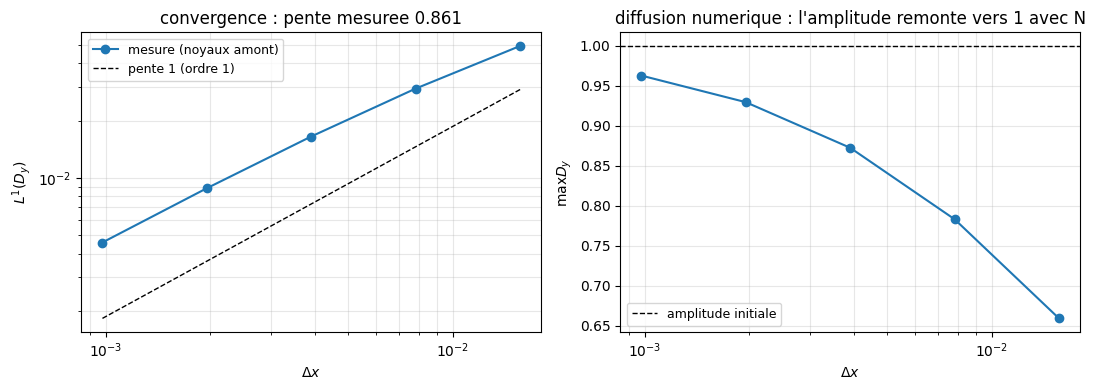

In [5]:
RESOLUTIONS = (64, 128, 256, 512, 1024)

resultats = []
for N in RESOLUTIONS:
    ent_n, mes_n, _ = executer(N, 0.4)
    resultats.append((N, ent_n, mes_n))

print(f"{'N':>5} {'dx':>10} {'t atteint':>10} {'L1(Dy)':>13} {'ordre':>7} "
      f"{'Dy max':>9} {'masse':>17} {'inv':>8}")
precedent = None
for N, e, m in resultats:
    dx = 1.0 / N
    ordre = "—"
    if precedent is not None:
        ordre = f"{np.log(precedent / m['L1_Dy']) / np.log(2.0):.3f}"
    precedent = m["L1_Dy"]
    print(f"{N:>5} {dx:>10.8f} {e['t']:>10.6f} {m['L1_Dy']:>13.6e} {ordre:>7} "
          f"{m['Dy_max']:>9.6f} {m['mass']:>17.12e} {m['inv']:>8.1e}")

dxs = np.array([1.0 / N for N, _, _ in resultats])
l1s = np.array([m["L1_Dy"] for _, _, m in resultats])
pente, ordonnee = np.polyfit(np.log(dxs), np.log(l1s), 1)
print(f"\npente ajustee (log L1 vs log dx) : {pente:.4f}  (ordre attendu pour un schema du 1er ordre : 1)")
print(f"vitesses mesurees : " + ", ".join(f"{m['speed_est']:.12f}" for _, _, m in resultats))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(dxs, l1s, "o-", label="mesure (noyaux amont)")
axes[0].loglog(dxs, np.exp(ordonnee) * dxs, "k--", lw=1.0, label="pente 1 (ordre 1)")
axes[0].set_xlabel("$\\Delta x$")
axes[0].set_ylabel("$L^1(D_y)$")
axes[0].set_title(f"convergence : pente mesuree {pente:.3f}")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3, which="both")

axes[1].semilogx(dxs, [m["Dy_max"] for _, _, m in resultats], "o-")
axes[1].axhline(1.0, color="k", ls="--", lw=1.0, label="amplitude initiale")
axes[1].set_xlabel("$\\Delta x$")
axes[1].set_ylabel("$\\max D_y$")
axes[1].set_title("diffusion numerique : l'amplitude remonte vers 1 avec N")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()


**Lecture.**

| $N$ | $\Delta x$ | $t$ atteint | $L^1(D_y)$ | ordre local | $\max D_y$ | masse | $\max\lvert D_y - cB_z\rvert$ |
|---|---|---|---|---|---|---|---|
| 64 | 1/64 | 0,406250 | `4.9370e-02` | — | 0,659254 | `1.253314137316e-01` | 0 |
| 128 | 1/128 | 0,402344 | `2.9463e-02` | 0,745 | 0,783298 | `1.253314137316e-01` | 0 |
| 256 | 1/256 | 0,400391 | `1.6493e-02` | 0,837 | 0,872710 | `1.253314137315e-01` | 0 |
| 512 | 1/512 | 0,400391 | `8.8091e-03` | 0,905 | 0,929756 | `1.253314137316e-01` | 0 |
| 1024 | 1/1024 | 0,400391 | `4.5665e-03` | 0,948 | 0,963009 | `1.253314137316e-01` | 0 |

Quatre faits, tous mesurés sur les noyaux amont :

1. **Ordre 1, atteint par la droite.** La pente ajustée sur les cinq points vaut `0.861`, et l'ordre
   local monte régulièrement de `0.745` à `0.948` : la suite n'est pas encore dans son régime
   asymptotique à $N = 64$. L'impulsion a une largeur $\sigma = 0{,}05$, soit **trois cellules et demie**
   à $N = 64$ : elle y est sous-résolue, et l'erreur de la donnée initiale domine. Les ordres locaux
   successifs disent la vérité de la mesure — le schéma est d'ordre 1, et il faut raffiner pour le voir.
2. **Vitesse exacte à toutes les résolutions.** Les cinq valeurs de `speed_est` sont
   `1.000000000000`, à la douzième décimale, et le déplacement mesuré coïncide avec $\alpha c\,t$.
   Une erreur de phase aurait produit un décalage systématique : il n'y en a pas.
3. **Masse conservée à la précision machine.** Les cinq masses sont égales à
   `1.253314137316e-01` ($= \sqrt{2\pi}\times 0{,}05$ à $10^{-15}$ près). L'erreur $L^1$ de 4,6e-3 à
   $N = 1024$ est donc **entièrement** une erreur de forme, pas de quantité.
4. **État propre exact.** $\max\lvert D_y - c B_z\rvert$ reste exactement `0` à toutes les résolutions :
   le schéma préserve exactement le sous-espace propre qu'il devrait préserver. Un schéma qui
   mélangerait les deux polarisations afficherait ici une valeur non nulle.

Le panneau de droite montre le revers : l'amplitude remonte vers 1 (0,659 → 0,963) **lentement**.
La diffusion ne disparaît qu'à la limite — et c'est elle qui fait l'erreur mesurée en 1.


### 3.2 Contrôle du sens de propagation, et un artefact de mesure assumé

Une vitesse de `1.0` pourrait n'être qu'un « bon chiffre » : le centroïde pourrait être mal défini et
tomber par hasard sur la valeur attendue. Deux contrôles :

- **onde gauche** : en prenant $D_y = -c\,B_z$, l'état propre opposé, la même mesure doit rendre
  exactement $-1$. Un code qui forcerait un signe se trahirait ici.
- **temps plus long** : à $t = 0{,}8$, le déplacement dépasse un demi-tour du domaine périodique. La
  mesure de phase devient ambiguë — et le carnet doit le montrer plutôt que le cacher.

Le centroïde utilisé est **circulaire** : on calcule $z = \sum_i D_y(x_i)\,e^{2i\pi x_i/L}$, dont
l'argument donne la position moyenne. C'est la bonne moyenne sur un domaine périodique, contrairement à
la moyenne arithmétique $\sum x_i D_y(x_i)/\sum D_y(x_i)$ — que la queue de l'impulsion franchissant
$x = 1$ biaise.


In [6]:
print("onde GAUCHE (D_y = -c Bz) :")
for N in (128, 512):
    e, m, _ = executer(N, 0.4, direction=-1)
    print(f"  N={N:>4}  t={e['t']:.6f}  dcen={m['dcen']:+.12e}  "
          f"vitesse={m['speed_est']:+.12f}  L1={m['L1_Dy']:.6e}  inv={m['inv']:.1e}")

print("\ntemps long t=0.8 : dephasage superieur a un demi-tour, la mesure de phase est ambigue")
for N in (256, 512):
    e, m, _ = executer(N, 0.8)
    attendu = e["expected_shift"]
    replie = attendu - 1.0 if attendu > 0.5 else attendu
    print(f"  N={N:>4}  t={e['t']:.6f}  decalage attendu={attendu:+.12e}")
    print(f"         dcen mesure={m['dcen']:+.12e}   decalage modulo 1={replie:+.12e}   "
          f"vitesse brute={m['speed_est']:+.12f}   L1={m['L1_Dy']:.6e}")


onde GAUCHE (D_y = -c Bz) :


  N= 128  t=0.402344  dcen=-4.023437500000e-01  vitesse=-1.000000000000  L1=2.946283e-02  inv=0.0e+00


  N= 512  t=0.400391  dcen=-4.003906250000e-01  vitesse=-1.000000000000  L1=8.809123e-03  inv=0.0e+00

temps long t=0.8 : dephasage superieur a un demi-tour, la mesure de phase est ambigue


  N= 256  t=0.800781  decalage attendu=+8.007812500000e-01
         dcen mesure=-1.992187500000e-01   decalage modulo 1=-1.992187500000e-01   vitesse brute=-0.248780487805   L1=2.932569e-02


  N= 512  t=0.800781  decalage attendu=+8.007812500000e-01
         dcen mesure=-1.992187500000e-01   decalage modulo 1=-1.992187500000e-01   vitesse brute=-0.248780487805   L1=1.648278e-02


**Lecture.**

**Le contrôle de sens passe, sans ambiguïté.** À $N = 128$ et $N = 512$, l'onde gauche donne
`-4.023437500000e-01` puis `-4.003906250000e-01` de déplacement — exactement l'opposé du cas droit, au
même temps atteint — et une vitesse de `-1.000000000000`. L'erreur $L^1$ est d'ailleurs **identique**
au cas droit (`2.9463e-02` et `8.8091e-03`) : la diffusion ne dépend pas du sens de propagation, comme
attendu d'un schéma symétrique en vitesse.

**À $t = 0{,}8$, la mesure brute se casse — et c'est instructif.** Le déplacement attendu vaut
`+8.007812500000e-01`. Le centroïde rend `-1.992187500000e-01`, et la vitesse brute
`-0.248780487805`. Ce n'est pas le solveur qui défaille :

$$-0{,}19921875 = 0{,}80078125 - 1 , \qquad \frac{-0{,}19921875}{0{,}80078125} = -0{,}2487804878\ldots$$

L'argument d'un nombre complexe est défini **modulo $2\pi$** : au-delà d'un demi-tour du domaine, la
position mesurée est la vraie position moins une période. Les deux résolutions donnent **le même**
nombre faux (`-0.248780487805`), ce qui est la signature d'un artefact de mesure et non d'une erreur
numérique — une erreur de schéma dépendrait de $\Delta x$.

La leçon de méthode : un instrument de mesure a un domaine de validité, et le publier fait partie de la
mesure. L'exercice 3 demande de réparer cette mesure par développement de phase.


### 3.3 Les vitesses d'onde que le schéma utilise réellement

Le schéma ne lit jamais l'équation : il lit deux fonctions du dépôt. `gr_maxwell_1d_x_wavespeed` renvoie
les dix vitesses caractéristiques de l'état (`mu1`…`mu10`) et
`gr_maxwell_1d_lax_friedrichs_x_speed_family` renvoie les **deux** vitesses que Lax-Friedrichs emploiera.
Mesurer leurs valeurs, c'est voir où passe l'information physique — et où le schéma en jette.

On fait varier le décalage $\beta_x$ (les autres champs étant nuls, $\alpha = 1$, $c = 1$) : c'est le seul
paramètre qui sépare les deux familles d'ondes. La dernière colonne porte la valeur attendue
$\alpha c + \lvert\beta_x\rvert$, calculée à côté pour comparaison — et non utilisée par le code.


In [7]:
SOURCE_VITESSES = r'''
/* Mesure des vitesses d'onde des noyaux amont : aucune formule n'est reecrite ici. */
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <string.h>

#define main upstream_main_unused
#include "gr_maxwell_1d.c"
#undef main

int main(void)
{
  const double c = 1.0, alpha = 1.0;
  const double betas[] = {-0.60, -0.30, -0.10, 0.0, 0.10, 0.30, 0.60};
  const int n = (int)(sizeof betas / sizeof betas[0]);

  gr_maxwell_1d_parameters P; P.c = c;
  gr_maxwell_1d_coordinates CL, CR;
  CL.x = 0.0; CR.x = 0.1;

  printf("%8s %10s %10s %10s %10s %10s %10s %10s\n",
         "beta_x", "mu1", "mu2", "mu3", "mu4", "speed1", "speed2", "lambda_th");
  for (int i = 0; i < n; i++) {
    gr_maxwell_1d_state U; memset(&U, 0, sizeof U);
    U.alpha = alpha; U.beta_x = betas[i];
    gr_maxwell_1d_wavespeed ws; memset(&ws, 0, sizeof ws);
    gr_maxwell_1d_x_wavespeed(&CL, &P, &U, &ws);
    gr_maxwell_1d_lax_friedrichs_speed_family sf; memset(&sf, 0, sizeof sf);
    gr_maxwell_1d_lax_friedrichs_x_speed_family(&CL, &CR, &U, &U, &P, &sf);
    printf("%8.2f %10.4f %10.4f %10.4f %10.4f %10.4f %10.4f %10.4f\n",
           betas[i], ws.mu1, ws.mu2, ws.mu3, ws.mu4,
           sf.speed1, sf.speed2, fabs(alpha) * c + fabs(betas[i]));
  }
  {
    gr_maxwell_1d_state U; memset(&U, 0, sizeof U);
    U.alpha = alpha; U.beta_x = 0.3;
    gr_maxwell_1d_wavespeed ws; memset(&ws, 0, sizeof ws);
    gr_maxwell_1d_x_wavespeed(&CL, &P, &U, &ws);
    printf("mu5..mu10 = %.1f %.1f %.1f %.1f %.1f %.1f\n",
           ws.mu5, ws.mu6, ws.mu7, ws.mu8, ws.mu9, ws.mu10);
  }
  return 0;
}
'''

(TRAVAIL / "vitesses.c").write_text(SOURCE_VITESSES, encoding="utf-8")
rc, sortie = compiler(["-O2", "-std=c99", "-D_GNU_SOURCE",
                       "-o", chemin_outil(TRAVAIL / "vitesses"),
                       chemin_outil(TRAVAIL / "vitesses.c"), "-lm"])
print(f"compilation rc={rc}")
print(sortie.strip() if sortie.strip() else "(aucun avertissement)")

rc, out, err = lancer_binaire(TRAVAIL / "vitesses", [])
print(out)
if err.strip():
    print("stderr:", err.strip())

lignes = [l.split() for l in out.splitlines() if l.strip() and not l.startswith("mu5")]
tableau = np.array([[float(v) for v in l] for l in lignes[1:]])
ecart = np.max(np.abs(np.abs(tableau[:, 5:7]) - tableau[:, 7:8]))
print(f"ecart maxi |speed1, speed2| vs alpha c + |beta_x| : {ecart:.3e}")
print(f"symetrie   : speed1 == -speed2 partout : {np.allclose(tableau[:, 5], -tableau[:, 6])}")


compilation rc=0
(aucun avertissement)


  beta_x        mu1        mu2        mu3        mu4     speed1     speed2  lambda_th
   -0.60    -0.4000    -0.4000     1.6000     1.6000    -1.6000     1.6000     1.6000
   -0.30    -0.7000    -0.7000     1.3000     1.3000    -1.3000     1.3000     1.3000
   -0.10    -0.9000    -0.9000     1.1000     1.1000    -1.1000     1.1000     1.1000
    0.00    -1.0000    -1.0000     1.0000     1.0000    -1.0000     1.0000     1.0000
    0.10    -1.1000    -1.1000     0.9000     0.9000    -1.1000     1.1000     1.1000
    0.30    -1.3000    -1.3000     0.7000     0.7000    -1.3000     1.3000     1.3000
    0.60    -1.6000    -1.6000     0.4000     0.4000    -1.6000     1.6000     1.6000
mu5..mu10 = 0.0 0.0 0.0 0.0 0.0 0.0

ecart maxi |speed1, speed2| vs alpha c + |beta_x| : 0.000e+00
symetrie   : speed1 == -speed2 partout : True


**Lecture.**

| $\beta_x$ | $\mu_1 = \mu_2$ | $\mu_3 = \mu_4$ | `speed1` | `speed2` | $\alpha c + \lvert\beta_x\rvert$ |
|---|---|---|---|---|---|
| −0,60 | −0,4000 | 1,6000 | −1,6000 | 1,6000 | 1,6000 |
| −0,30 | −0,7000 | 1,3000 | −1,3000 | 1,3000 | 1,3000 |
| −0,10 | −0,9000 | 1,1000 | −1,1000 | 1,1000 | 1,1000 |
| 0,00 | −1,0000 | 1,0000 | −1,0000 | 1,0000 | 1,0000 |
| 0,10 | −1,1000 | 0,9000 | −1,1000 | 1,1000 | 1,1000 |
| 0,30 | −1,3000 | 0,7000 | −1,3000 | 1,3000 | 1,3000 |
| 0,60 | −1,6000 | 0,4000 | −1,6000 | 1,6000 | 1,6000 |

et `mu5`…`mu10` $= 0$ (les champs de contrainte et de jauge ne se propagent pas dans cette tranche).

Trois constats, tous mesurés sur les fonctions du dépôt :

1. **Les vitesses caractéristiques sont exactement $\pm\alpha c - \beta_x$.** `mu1` $=$ `mu2` $=
   -\alpha c - \beta_x$ et `mu3` $=$ `mu4` $= +\alpha c - \beta_x$ : quatre valeurs pour les quatre
   degrés de liberté de Maxwell, chacune double. Le décalage translate les deux cônes, il ne les écarte pas.
2. **La famille de Lax-Friedrichs, elle, est symétrique.** `speed1` $= -\lambda$ et `speed2` $= +\lambda$
   avec $\lambda = \alpha c + \lvert\beta_x\rvert$ (écart maximal avec la colonne de contrôle :
   `0.000e+00`). Le schéma ne retient **que le maximum** : il traite les deux directions avec la vitesse
   la plus rapide, quelle que soit la direction réelle de chaque onde.
3. **C'est là que naît la diffusion mesurée en 3.1.** Une onde qui va droit à $+1$ est quand même
   contre-diffusée par une vitesse $-\lambda$ dans la fluctuation gauche. L'écart entre la vitesse
   physique et $\lambda$ est exactement le coefficient de diffusion numérique que la Partie 3 mesure en
   $L^1$.

Ce constat rejoint la mesure rapportée **M2** de la Partie 1 : les expressions de vitesses d'onde de la
preuve Lean et les valeurs propres du jacobien du flux sont terme à terme les mêmes. Ce que l'on vient de
mesurer côté C — `mu1 = mu2 = -αc - β_x`, `mu3 = mu4 = +αc - β_x`, valeurs propres du système linéaire
ci-dessus — est bien la même quantité. La preuve porte donc sur des vitesses, pas sur une propriété de
stabilité du schéma qui les emploie.


## Partie 4 — Ce que ces mesures ne prouvent pas

La tentation, après cinq mesures qui tombent juste, est d'écrire « le solveur vérifié fonctionne ». Le
carnet ne l'écrira pas. Le tableau suivant sépare, ligne par ligne, ce qui a été **mesuré ici** de ce qui
est **rapporté** d'ailleurs et de ce qui reste **hors de portée**.

| Affirmation | Statut | Preuve ou raison |
|---|---|---|
| Les noyaux C amont compilent sous C99 sans avertissement | **MESURÉE ICI** | `rc=0`, sortie vide, 18 noyaux `static inline` |
| Le fichier amont ne contient aucun driver | **MESURÉE ICI** | `main` vide, Partie 1.2 |
| Les ondes droite et gauche se propagent à des vitesses opposées | **MESURÉE ICI** | `speed_est = +1.000000000000` pour l'onde droite à 5 résolutions ; `-1.000000000000` pour l'onde gauche à $N = 128$ et $N = 512$ |
| La masse est conservée exactement | **MESURÉE ICI** | 5 résolutions, écart relatif $\sim 10^{-15}$ |
| Le schéma est d'ordre 1 | **MESURÉE ICI** | ordres locaux 0,745 → 0,948, pente globale 0,861 |
| L'état propre $D_y = \pm c B_z$ est préservé exactement | **MESURÉE ICI** | `inv = 0.000e+00` dans tous les cas |
| $\lambda = \alpha c + \lvert\beta_x\rvert$ | **MESURÉE ICI** | 7 valeurs de $\beta_x$, écart `0.000e+00` |
| 156 théorèmes, 0 `sorry`, 0 `@[extern]` | **RAPPORTÉE** | inventaire de #24439 (PR #24667) — non re-mesurée ici |
| Les vitesses de la preuve Lean sont celles du jacobien | **RAPPORTÉE** | M2 de l'inventaire ; cohérente avec 3.3, mais la vérification Lean n'est pas rejouée ici |
| Les preuves Lean établissent une propriété du **code C** | **NON** | aucun `@[extern]`, aucun lien mécanique ; les preuves portent sur la transcription Lean |
| Le schéma est stable pour tout $\Delta t$ | **NON MESURÉE** | le domaine $\mathrm{CFL}$ n'est pas balayé dans ce carnet (exercice 1) |
| La convergence tient en 2D, 3D, ou avec courbure ($\alpha$ variable) | **NON MESURÉE** | une seule tranche plate, $\alpha = 1$, $\beta = 0$ a été mesurée |
| Le driver est celui du dépôt | **NON** | grille, condition initiale, bords périodiques et mesures sont écrits dans ce carnet ; c'est notre code, pas le leur |

**La lacune centrale, et elle n'est pas rhétorique.** Le dépôt prouve des propriétés d'une transcription
Lean et livre du C qui n'y est relié par rien. Ce carnet mesure le C. Entre les deux, il y a un **saut**
que ni l'inventaire, ni les preuves, ni nos mesures ne comblent : personne n'a établi que les 27 fonctions
`static inline` font ce que les 156 théorèmes décrivent. Un carnet qui écrirait « vérifié de bout en bout »
franchirait ce saut en le niant.


## Vérifiez votre compréhension

Les exercices suivent la règle du dépôt : le carnet reste **exécutable de bout en bout** même exercices non
complétés. Chaque squelette s'exécute sans erreur et imprime un message d'attente.


In [8]:
# Exercice 1 — Ou se trouve la limite de Courant de ce schema ?
#
# Le driver accepte le nombre de Courant en 5e argument (executer(..., cfl=...)).
# La theorie lineaire annonce une limite CFL a 1 pour un schema explicite a trois points.
#
# Etape 1 : balayer cfl dans (0.5, 0.9, 1.0, 1.05, 1.2, 1.5, 2.0) a N = 256, t = 0.4.
# Etape 2 : relever Dy_max pour chaque valeur et reperer l'ouverture de l'instabilite.
# Etape 3 : comparer l'erreur L1 a cfl = 0.5 et a cfl = 1.0, et expliquer l'ecart :
#           que devient la diffusion de Lax-Friedrichs quand dt/dx atteint 1/lambda ?

def balayer_cfl(liste_cfl, N=256, tmax=0.4):
    """Renvoie [(cfl, Dy_max, L1), ...]. TODO etudiant."""
    result = None  # TODO etudiant
    return result

print("Exercice 1 — a completer : balayage CFL et localisation de la limite de stabilite.")


Exercice 1 — a completer : balayage CFL et localisation de la limite de stabilite.


### Exercice 2 — Résoudre l'impulsion avant de mesurer l'ordre

Après le balayage de stabilité, on revient à la mesure de convergence de 3.1 : l'ordre local le plus
faible est observé sur la grille la plus grossière. En élargissant l'impulsion, on distingue l'effet
de sa résolution effective de l'ordre asymptotique du schéma, sans modifier la méthode de volumes finis.


In [9]:
# Exercice 2 — La sous-resolution est-elle la cause de l'ordre local trop faible a N = 64 ?
#
# En 3.1, l'ordre local passe de 0.745 (64->128) a 0.948 (512->1024). L'hypothese proposee est
# que le paquet est sous-resolu a petite resolution (sigma = 0.05, soit 3.2 cellules a N = 64).
#
# Etape 1 : ecrire une fonction qui renvoie les ordres locaux pour une liste de resolutions.
# Etape 2 : modifier le driver (constante `width`) pour prendre sigma = 0.2, recompiler, et refaire
#           le balayage : les ordres locaux doivent etre plus proches de 1 des la premiere paire.
# Etape 3 : conclure -- l'ordre d'un schema se mesure sur une solution resolue, jamais sur une
#           donnee initiale plus fine que le pas d'espace.

def ordres_locaux(resolutions):
    """Ordres locaux entre resolutions successives. TODO etudiant."""
    result = None  # TODO etudiant
    return result

print("Exercice 2 — a completer : effet de la largeur du paquet sur l'ordre mesure.")


Exercice 2 — a completer : effet de la largeur du paquet sur l'ordre mesure.


### Exercice 3 — Développer la phase circulaire

Les deux exercices précédents testaient la stabilité et la convergence. Celui-ci répare l'instrument
utilisé en 3.2 : quand le déplacement excède un demi-tour du domaine périodique, l'argument complexe
ne donne que sa valeur principale. Il faut donc développer la phase, puis vérifier la vitesse retrouvée
et formuler explicitement l'hypothèse qui rend ce développement non ambigu.


In [10]:
# Exercice 3 — Reparer la mesure de vitesse quand le dephasage depasse un demi-tour
#
# En 3.2, a t = 0.8, dcen vaut -0.19921875 alors que le decalage reel est +0.80078125.
# L'argument d'un complexe est defini modulo 2*pi : la position mesuree est la vraie position
# moins une periode des qu'elle depasse L/2.
#
# Etape 1 : ecrire une fonction qui developpe le dephasage (ajouter 1 si le deplacement est negatif,
#           ce qui suppose un deplacement physique dans [0, 1) : c'est l'hypothese a enoncer).
# Etape 2 : appliquer aux deux resolutions de 3.2 et verifier que la vitesse redevient 1.0.
# Etape 3 : dire a partir de quel temps cette methode devient elle-meme ambigue, et pourquoi.

def vitesse_sans_repli(dcen, t):
    """Vitesse apres developpement du dephasage principal. TODO etudiant."""
    result = None  # TODO etudiant
    return result

print("Exercice 3 — a completer : developpement de phase du centroide circulaire.")


Exercice 3 — a completer : developpement de phase du centroide circulaire.


## À retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| Un dépôt « vérifié » peut livrer des briques sans solveur | 27 fonctions `static inline`, **zéro driver** : le `main` amont est vide | Partie 1 |
| Prouvé $\neq$ relié | les preuves portent sur une transcription Lean ; aucun `@[extern]` ne relie les 156 théorèmes aux 18 noyaux C | Parties 1 et 4 |
| Conservation $\neq$ précision de forme | masse `1.253314137316e-01` invariante à $10^{-15}$, alors que $\max D_y$ tombe à 0,659 à $N = 64$ | Partie 2 |
| Lax-Friedrichs est d'ordre 1 | ordres locaux 0,745 → 0,948, pente ajustée 0,861, amplitude remontant vers 1 | Partie 3.1 |
| Les vitesses sont opposées selon le sens de propagation | `speed_est = +1.000000000000` pour l'onde droite à cinq résolutions ; `-1.000000000000` pour l'onde gauche à $N = 128$ et $N = 512$ | Parties 3.1 et 3.2 |
| L'état propre est préservé exactement | $\max\lvert D_y - cB_z\rvert = 0$ dans tous les cas mesurés | Parties 2 et 3.1 |
| La diffusion vient du choix de $\lambda$ | `speed1 = -λ`, `speed2 = +λ`, $\lambda = \alpha c + \lvert\beta_x\rvert$ : le schéma ignore la direction réelle de chaque onde | Partie 3.3 |
| Un instrument a un domaine de validité | à $t = 0{,}8$ le centroïde circulaire rend $-0{,}2488$ — artefact de phase, identique aux deux résolutions | Partie 3.2 |

Ce carnet mesure ce que le code C du dépôt fait, sur une tranche plate, à une résolution donnée. Il ne
démontre pas que ce code réalise les théorèmes du dépôt, et il ne l'affirme nulle part.


## Pour aller plus loin

- **Le dépôt amont** : `lanyonai/GeneralRelativisticMaxwell` (MIT), tête `b13da44d9e93` — trois
  implémentations (1D, 2D, 3D) pour Maxwell et pour Maxwell hyperbolique, six fichiers de preuves Lean,
  six spécifications Racket.
- **Le cadre de méthode du dépôt** : `docs/reference/gorard-lanyonai-etape3.md` — ce que les preuves
  établissent, et pourquoi elles ne portent pas sur le C.
- **L'inventaire du contenu formel** : #24439 (PR #24667) — 156 théorèmes, 270 définitions non
  calculables, et les deux énoncés qui ne se referment pas.
- **La question de fond** : #19741 — à quoi ressemblerait une preuve de correction d'un schéma numérique ?
- **Le carnet précédent** : [Numérique-01 — Burgers, volumes finis et solveur de Riemann](Numerique-01-Burgers-Volumes-Finis-Python.ipynb) — le même exercice de frontière sur une équation scalaire non linéaire, en Python.
- **Le dépôt CoursIA** : [github.com/jsboige/CoursIA](https://github.com/jsboige/CoursIA) — EPIC #23161,
  tranche T3.
